In [ ]:
# Create folders for raw and processed data
!mkdir -p data/raw data/processed

# Download the Sentiment140 dataset
!wget -O data/raw/trainingandtestdata.zip \
  https://cs.stanford.edu/people/alecmgo/trainingandtestdata.zip

# Extract the downloaded dataset
!unzip -o data/raw/trainingandtestdata.zip -d data/raw

--2026-10-18 15:05:51--  https://cs.stanford.edu/people/alecmgo/trainingandtestdata.zip
Resolving cs.stanford.edu (cs.stanford.edu)... 171.64.64.64
Connecting to cs.stanford.edu (cs.stanford.edu)|171.64.64.64|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 81363704 (78M) [application/zip]
Saving to: ‘data/raw/trainingandtestdata.zip’

data/raw/trainingan 100%[===================>]  77.59M  6.66MB/s    in 9.6s    

2026-10-18 15:06:01 (8.04 MB/s) - ‘data/raw/trainingandtestdata.zip’ saved [81363704/81363704]

Archive:  data/raw/trainingandtestdata.zip
  inflating: data/raw/testdata.manual.2009.06.14.csv  
  inflating: data/raw/training.1600000.processed.noemoticon.csv  


In [ ]:
import os

print(os.listdir("data/raw"))

['training.1600000.processed.noemoticon.csv', 'testdata.manual.2009.06.14.csv', 'trainingandtestdata.zip']


In [ ]:
"""
Sentiment140 Dataset Splitting

- Load the original Stanford CSV files (6 columns, no header).
- Split 1.6 million automatically labelled tweets into
  training, validation, and test sets using an 80:10:10 ratio.
- Use stratified sampling to preserve class distributions.
- Save the 498 manually labelled tweets as a separate test set.
"""

import pandas as pd
from sklearn.model_selection import train_test_split
import os

# Set project directories for Google Colab
BASE_DIR = os.getcwd()
RAW_DIR = os.path.join(BASE_DIR, "data", "raw")
PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed")

# Ensure the output directory exists
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Fixed random seed for reproducibility
RANDOM_STATE = 42

# Original Stanford CSV column names (6 columns, no header)
COLUMNS = ["sentiment", "id", "date", "flag", "user", "text"]


# ==================================================
# Step 1: Load the original dataset
# ==================================================

print("=" * 50)
print("Step 1: Loading original data...")
print("=" * 50)

# Load 1.6 million automatically labelled tweets
train_full = pd.read_csv(
    os.path.join(
        RAW_DIR,
        "training.1600000.processed.noemoticon.csv"
    ),
    encoding="latin-1",
    names=COLUMNS
)

print(f"Total automatically labelled tweets: {len(train_full):,}")

# Load 498 manually labelled tweets
manual_test = pd.read_csv(
    os.path.join(
        RAW_DIR,
        "testdata.manual.2009.06.14.csv"
    ),
    encoding="latin-1",
    names=COLUMNS
)

print(f"Total manually labelled tweets: {len(manual_test):,}")

# Examine sentiment label distributions
print("\nOriginal training label distribution:")
print(train_full["sentiment"].value_counts().sort_index())

print("\nManual test label distribution:")
print(manual_test["sentiment"].value_counts().sort_index())

# Keep only negative (0) and positive (4) labels
train_full = train_full[
    train_full["sentiment"].isin([0, 4])
].copy()

print(
    f"\nSamples remaining after removing neutral labels: "
    f"{len(train_full):,}"
)

# Convert sentiment labels:
# 0 = Negative, 4 -> 1 = Positive
train_full["label"] = train_full["sentiment"].apply(
    lambda x: 1 if x == 4 else 0
)

# Select text and label columns
df = train_full[["text", "label"]].copy()

print(f"\nFinal dataset size: {len(df):,}")
print(f"Positive tweets: {(df['label'] == 1).sum():,}")
print(f"Negative tweets: {(df['label'] == 0).sum():,}")


# ==================================================
# Step 2: Stratified train/validation/test split
# ==================================================

print("\n" + "=" * 50)
print("Step 2: Stratified data splitting (80:10:10)...")
print("=" * 50)

# First split: 90% train+validation, 10% test
train_val_df, test_df = train_test_split(
    df,
    test_size=0.1,
    random_state=RANDOM_STATE,
    stratify=df["label"]
)

# Second split: 80% train, 10% validation
# Validation is 1/9 of the remaining 90%
train_df, val_df = train_test_split(
    train_val_df,
    test_size=1/9,
    random_state=RANDOM_STATE,
    stratify=train_val_df["label"]
)

# Display dataset sizes
print(
    f"\nTrain: {len(train_df):,} "
    f"({len(train_df)/len(df)*100:.1f}%)"
)

print(
    f"Validation: {len(val_df):,} "
    f"({len(val_df)/len(df)*100:.1f}%)"
)

print(
    f"Test: {len(test_df):,} "
    f"({len(test_df)/len(df)*100:.1f}%)"
)

# Verify class distributions
print("\nClass distribution across datasets:")

for name, d in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    pos = (d["label"] == 1).sum()
    neg = (d["label"] == 0).sum()

    print(
        f"{name}: "
        f"Positive={pos:,} ({pos/len(d)*100:.1f}%), "
        f"Negative={neg:,} ({neg/len(d)*100:.1f}%)"
    )


# ==================================================
# Step 3: Save processed datasets
# ==================================================

print("\n" + "=" * 50)
print("Step 3: Saving processed datasets...")
print("=" * 50)

# Save training, validation, and test datasets
train_df.to_csv(
    os.path.join(PROCESSED_DIR, "train.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(PROCESSED_DIR, "val.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(PROCESSED_DIR, "test.csv"),
    index=False
)

# Convert labels for the manually labelled test set
# 0 = Negative, 1 = Positive, 2 = Neutral
manual_test["label"] = manual_test["sentiment"].apply(
    lambda x: 1 if x == 4 else (0 if x == 0 else 2)
)

# Save manual test data separately
manual_test[["text", "label"]].to_csv(
    os.path.join(PROCESSED_DIR, "manual_test.csv"),
    index=False
)

print("\nProcessed datasets saved to data/processed/")

print(f"  - train.csv ({len(train_df):,} samples)")
print(f"  - val.csv ({len(val_df):,} samples)")
print(f"  - test.csv ({len(test_df):,} samples)")
print(f"  - manual_test.csv ({len(manual_test):,} samples)")

print("\n" + "=" * 50)
print(f"Data splitting completed! Random seed = {RANDOM_STATE}")
print("=" * 50)

Step 1: Loading original data...
Total automatically labelled tweets: 1,600,000
Total manually labelled tweets: 498

Original training label distribution:
sentiment
0    800000
4    800000
Name: count, dtype: int64

Manual test label distribution:
sentiment
0    177
2    139
4    182
Name: count, dtype: int64

Samples remaining after removing neutral labels: 1,600,000

Final dataset size: 1,600,000
Positive tweets: 800,000
Negative tweets: 800,000

Step 2: Stratified data splitting (80:10:10)...

Train: 1,280,000 (80.0%)
Validation: 160,000 (10.0%)
Test: 160,000 (10.0%)

Class distribution across datasets:
Train: Positive=640,000 (50.0%), Negative=640,000 (50.0%)
Validation: Positive=80,000 (50.0%), Negative=80,000 (50.0%)
Test: Positive=80,000 (50.0%), Negative=80,000 (50.0%)

Step 3: Saving processed datasets...

Processed datasets saved to data/processed/
  - train.csv (1,280,000 samples)
  - val.csv (160,000 samples)
  - test.csv (160,000 samples)
  - manual_test.csv (498 samples)


2. Exploratory Data Analysis (EDA)

2.1 Dataset Overview and Data Quality

Before developing the baseline classification model, we examine the structure and quality of the Sentiment140 dataset.

This analysis focuses on dataset dimensions, variable types, missing values, duplicate records, and sentiment label distributions.

In [ ]:
import pandas as pd

# Load the training dataset
train_df = pd.read_csv("data/processed/train.csv")

# Display dataset dimensions
print("Dataset shape:", train_df.shape)

# Display the first five rows
display(train_df.head())

# Examine data types and non-null counts
train_df.info()

# Check missing values
print("\nMissing values:")
print(train_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", train_df.duplicated().sum())

Dataset shape: (1280000, 2)


,text,label
0,A nice sunny day but too windy to fly,0
1,@styleit Never made it to Mac Pro -- but I agr...,1
2,im watchin Alladin on Disney XD,1
3,"ok, now let`s get to work",0
4,"@meghansoper Well Meg, no need for Jealous! Th...",1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1280000 entries, 0 to 1279999
Data columns (total 2 columns):
 #   Column  Non-Null Count    Dtype 
---  ------  --------------    ----- 
 0   text    1280000 non-null  object
 1   label   1280000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 19.5+ MB

Missing values:
text     0
label    0
dtype: int64

Duplicate rows: 11948


Data Quality Observations

The training dataset contains 1,280,000 tweets and two variables: text and label. The text column contains tweet content, while label represents binary sentiment classification (0 = negative, 1 = positive).

No missing values were detected in either column. However, 11,948 duplicate rows were identified, accounting for approximately 0.93% of the training dataset.

These duplicate records require further investigation before deciding whether they should be removed. In particular, duplicate texts across training and evaluation datasets may introduce data leakage and affect the reliability of model performance estimates.

In [ ]:
# Count repeated tweet texts, regardless of label
text_duplicates = train_df.duplicated(subset=["text"]).sum()

# Count repeated full records
full_duplicates = train_df.duplicated().sum()

# Check how many unique texts have conflicting sentiment labels
label_conflicts = (
    train_df.groupby("text")["label"]
    .nunique()
    .gt(1)
    .sum()
)

print("Duplicate text rows:", text_duplicates)
print("Duplicate full rows:", full_duplicates)
print("Texts with conflicting labels:", label_conflicts)

# Load validation and test datasets
val_df = pd.read_csv("data/processed/val.csv")
test_df = pd.read_csv("data/processed/test.csv")

# Identify overlapping texts between datasets
train_texts = set(train_df["text"])
val_texts = set(val_df["text"])
test_texts = set(test_df["text"])

print("Train-Val overlap:", len(train_texts & val_texts))
print("Train-Test overlap:", len(train_texts & test_texts))
print("Val-Test overlap:", len(val_texts & test_texts))


Duplicate text rows: 13431
Duplicate full rows: 11948
Texts with conflicting labels: 1483
Train-Val overlap: 1898
Train-Test overlap: 1899
Val-Test overlap: 534


### Duplicate Records and Data Quality

The training dataset contains 13,431 duplicate text rows and 11,948 exact duplicate records. Additionally, 1,483 unique texts were associated with conflicting sentiment labels.

Cross-dataset analysis identified 1,898 overlapping texts between the training and validation sets, 1,899 between the training and test sets, and 534 between the validation and test sets.

These overlapping texts may lead to overly optimistic model evaluation results. Therefore, this limitation should be considered when interpreting model performance.

2.2 Sentiment Distribution

This section examines the distribution of positive and negative sentiment labels in the training dataset to identify potential class imbalance.

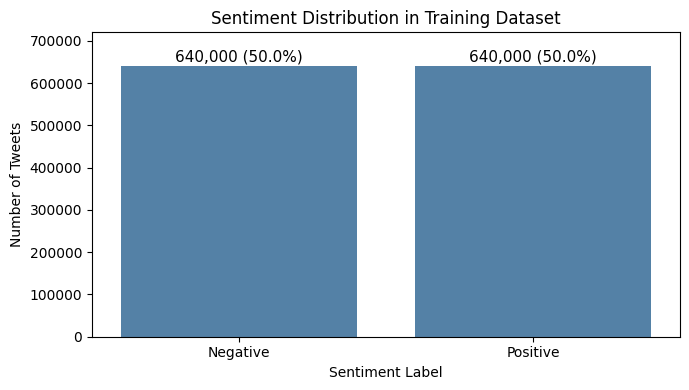

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate sentiment distribution
sentiment_counts = train_df["label"].value_counts().sort_index()

# Create bar chart
plt.figure(figsize=(7, 4))

ax = sns.barplot(
    x=["Negative", "Positive"],
    y=sentiment_counts.values,
    color="steelblue"
)

# Add count and percentage labels
for i, count in enumerate(sentiment_counts.values):
    ax.text(
        i, count + 10000,
        f"{count:,} (50.0%)",
        ha="center",
        fontsize=11
    )

plt.title("Sentiment Distribution in Training Dataset")
plt.xlabel("Sentiment Label")
plt.ylabel("Number of Tweets")
plt.ylim(0, 720000)
plt.tight_layout()
plt.show()

**Observation:**

The training dataset contains 640,000 negative tweets and 640,000 positive tweets, each accounting for 50% of the total samples.

This indicates a balanced class distribution, with no class imbalance observed in the training dataset.

2.3 Tweet Length Analysis

This section examines the length of tweets in terms of character count and word count. It also compares text lengths between positive and negative tweets to identify potential differences in their distributions.

In [ ]:
# Calculate tweet length in characters
train_df["char_count"] = train_df["text"].str.len()

# Calculate tweet length in words
train_df["word_count"] = train_df["text"].str.split().str.len()

# Summary statistics
print("Overall Tweet Length Statistics:")
display(train_df[["char_count", "word_count"]].describe())

# Compare positive and negative tweets
print("\nTweet Length by Sentiment:")
display(
    train_df.groupby("label")[["char_count", "word_count"]]
    .agg(["mean", "median", "std"])
    .round(2)
)

Overall Tweet Length Statistics:


,char_count,word_count
count,1.280000e+06,1.280000e+06
mean,7.409268e+01,1.317531e+01
std,3.642867e+01,6.956204e+00
min,6.000000e+00,1.000000e+00
25%,4.400000e+01,7.000000e+00
50%,6.900000e+01,1.200000e+01
75%,1.040000e+02,1.900000e+01
max,3.740000e+02,6.400000e+01



Tweet Length by Sentiment:


char_count               word_count             
            mean median    std       mean median   std
label                                                 
0          74.31   70.0  36.74      13.58   13.0  7.07
1          73.88   69.0  36.12      12.77   12.0  6.81

**Observation: Tweet Length Analysis**

The training dataset contains relatively short texts, with an average of 74.09 characters and 13.18 words per tweet. The median lengths are 69 characters and 12 words, respectively.

Negative tweets have slightly higher average character counts (74.31 vs. 73.88) and word counts (13.58 vs. 12.77) than positive tweets. However, these differences are small, suggesting that tweet length alone may have limited discriminative power for sentiment classification.

The maximum observed lengths are 374 characters and 64 words, indicating the presence of some unusually long records that may warrant further inspection.

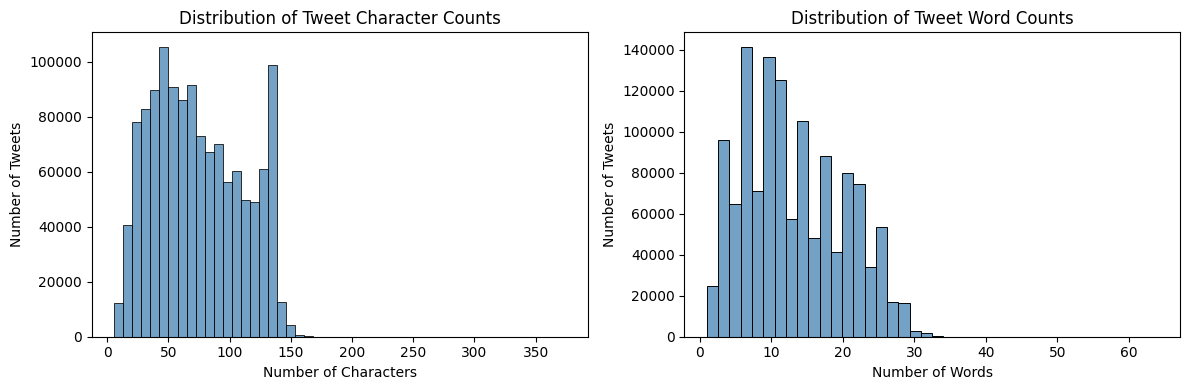

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Character count distribution
sns.histplot(
    train_df["char_count"],
    bins=50,
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Distribution of Tweet Character Counts")
axes[0].set_xlabel("Number of Characters")
axes[0].set_ylabel("Number of Tweets")

# Word count distribution
sns.histplot(
    train_df["word_count"],
    bins=40,
    ax=axes[1],
    color="steelblue"
)

axes[1].set_title("Distribution of Tweet Word Counts")
axes[1].set_xlabel("Number of Words")
axes[1].set_ylabel("Number of Tweets")

plt.tight_layout()
plt.show()

**Observation: Tweet Length Distribution**

Most tweets contain approximately 20–140 characters and 5–25 words. The distributions show some right-skewness, with a small number of longer tweets. A noticeable peak appears near 140 characters in the character count distribution.


### 2.4 Word Frequency Analysis

This section examines the most frequently occurring words in positive and negative tweets. The objective is to identify common vocabulary patterns and explore potential differences in word usage across sentiment categories.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Use a sample to make exploratory analysis more efficient
sample_df = train_df.sample(
    n=100000,
    random_state=42
)

# Function to extract the most frequent words
def get_top_words(texts, n=20):
    vectorizer = CountVectorizer(
        stop_words="english",
        max_features=5000
    )

    X = vectorizer.fit_transform(texts)

    word_counts = X.sum(axis=0).A1
    words = vectorizer.get_feature_names_out()

    return pd.DataFrame({
        "word": words,
        "frequency": word_counts
    }).sort_values(
        "frequency", ascending=False
    ).head(n)

# Positive tweets
positive_words = get_top_words(
    sample_df[sample_df["label"] == 1]["text"]
)

# Negative tweets
negative_words = get_top_words(
    sample_df[sample_df["label"] == 0]["text"]
)

print("Top 20 Words in Positive Tweets:")
display(positive_words)

print("Top 20 Words in Negative Tweets:")
display(negative_words)

Top 20 Words in Positive Tweets:


,word,frequency
2389,just,3875
1844,good,3764
2660,love,3015
1161,day,2915
2147,http,2898
3506,quot,2851
2574,like,2404
941,com,2210
4367,thanks,2191
2624,lol,2173


Top 20 Words in Negative Tweets:


,word,frequency
2405,just,4001
4888,work,2875
2576,like,2584
1180,day,2474
4441,today,2360
1871,going,2126
1334,don,2119
1894,got,2089
2222,im,2006
3535,really,1964


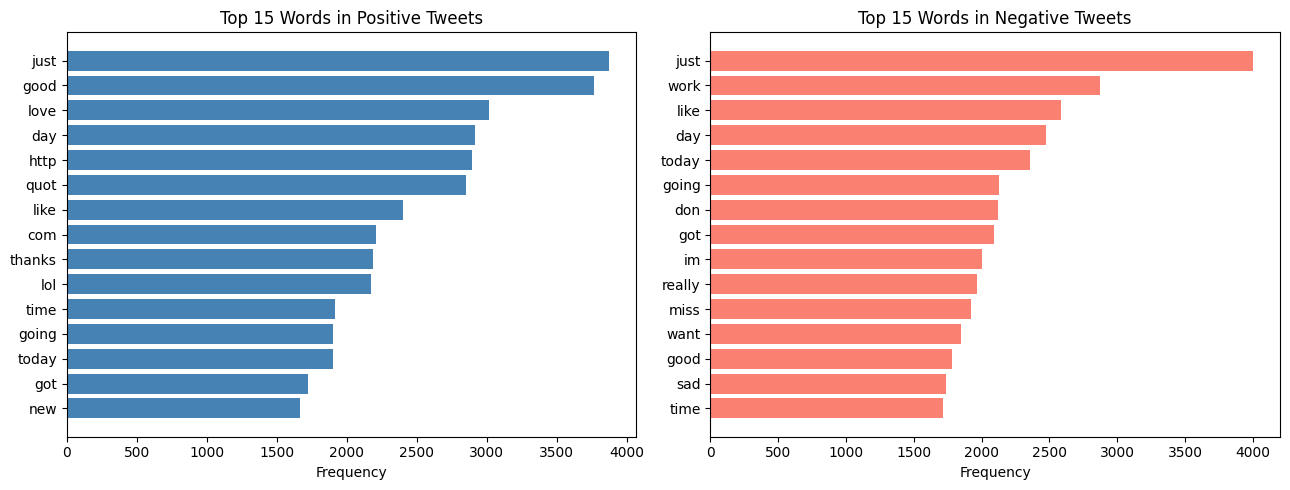

In [ ]:
import matplotlib.pyplot as plt

# Select top 15 words
positive_top = positive_words.head(15).iloc[::-1]
negative_top = negative_words.head(15).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Positive tweets
axes[0].barh(
    positive_top["word"],
    positive_top["frequency"],
    color="steelblue"
)
axes[0].set_title("Top 15 Words in Positive Tweets")
axes[0].set_xlabel("Frequency")

# Negative tweets
axes[1].barh(
    negative_top["word"],
    negative_top["frequency"],
    color="salmon"
)
axes[1].set_title("Top 15 Words in Negative Tweets")
axes[1].set_xlabel("Frequency")

plt.tight_layout()
plt.show()

Observation: Word Frequency Analysis

Positive tweets frequently contain words such as "good", "love", "thanks", and "great", while negative tweets commonly include words such as "work", "miss", and "sad".

Several words, including "just", "like", and "day", appear frequently in both sentiment categories, indicating that word frequency alone may not be sufficient to distinguish sentiment.

Additionally, tokens such as "http", "com", "quot", and "amp" suggest the presence of URLs and HTML-encoded text. These findings highlight the importance of appropriate text preprocessing before model training.

## 3. Traditional Machine Learning Baseline

### 3.1 Text Preprocessing

Before training the Logistic Regression model, tweet texts are preprocessed to reduce noise and improve consistency.

The preprocessing steps include HTML entity decoding, URL removal, username mention normalization, lowercase conversion, and whitespace normalization. Negation words are preserved to retain important sentiment information.

In [ ]:
import re
import html

def clean_text(text):
    # Decode HTML entities
    text = html.unescape(str(text))

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Replace username mentions
    text = re.sub(r'@\w+', ' usermention ', text)

    # Normalize whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Test the preprocessing function
examples = [
    "I LOVE this movie! http://example.com",
    "@john I don't like this weather",
    "Music &amp; movies are great!"
]

for text in examples:
    print("Original:", text)
    print("Cleaned: ", clean_text(text))
    print()

Original: I LOVE this movie! http://example.com
Cleaned:  i love this movie!

Original: @john I don't like this weather
Cleaned:  usermention i don't like this weather

Original: Music &amp; movies are great!
Cleaned:  music & movies are great!



In [ ]:
# Apply text preprocessing to all datasets
train_df["clean_text"] = train_df["text"].apply(clean_text)
val_df["clean_text"] = val_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

# Compare original and cleaned tweets
display(train_df[["text", "clean_text", "label"]].head(10))

# Check for empty texts after preprocessing
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    empty_count = df["clean_text"].eq("").sum()
    print(f"{name} empty texts: {empty_count}")

,text,clean_text,label
0,A nice sunny day but too windy to fly,a nice sunny day but too windy to fly,0
1,@styleit Never made it to Mac Pro -- but I agr...,usermention never made it to mac pro -- but i ...,1
2,im watchin Alladin on Disney XD,im watchin alladin on disney xd,1
3,"ok, now let`s get to work","ok, now let`s get to work",0
4,"@meghansoper Well Meg, no need for Jealous! Th...","usermention well meg, no need for jealous! the...",1
5,is having a lovely last night in Thames with M...,is having a lovely last night in thames with m...,1
6,"@JimmyLe1 dude, aren't those the best? w/the f...","usermention dude, aren't those the best? w/the...",1
7,I love @mjpoke ! @vendittoli where r u today? ...,i love usermention ! usermention where r u tod...,0
8,"@eyalbd1 $SPY, you got it,'you are a nut'","usermention $spy, you got it,'you are a nut'",1
9,Just seen Observe &amp; Report.....wasnt as go...,just seen observe & report.....wasnt as good a...,0


Train empty texts: 18
Validation empty texts: 4
Test empty texts: 0


**Observation: Text Preprocessing**

The preprocessing procedure successfully standardized tweet texts through HTML entity decoding, URL removal, username mention normalization, lowercase conversion, and whitespace normalization.

After preprocessing, 18 empty texts were identified in the training set and 4 in the validation set, while none were found in the test set.

These empty records were retained, as they represent only a small proportion of the dataset. However, they contain no remaining textual information for sentiment classification.

### 3.2 TF-IDF Feature Extraction

TF-IDF (Term Frequency–Inverse Document Frequency) is used to convert preprocessed tweet texts into numerical feature vectors for sentiment classification.

Both unigrams (single words) and bigrams (two consecutive words) are considered to capture individual terms and local word combinations.

The TF-IDF vectorizer is fitted only on the training set to prevent information leakage from the validation and test sets.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=5,
    sublinear_tf=True
)

# Fit on training data only
X_train = tfidf.fit_transform(train_df["clean_text"])

# Transform validation and test sets
X_val = tfidf.transform(val_df["clean_text"])
X_test = tfidf.transform(test_df["clean_text"])

# Extract sentiment labels
y_train = train_df["label"]
y_val = val_df["label"]
y_test = test_df["label"]

# Display feature dimensions
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training features: (1280000, 50000)
Validation features: (160000, 50000)
Test features: (160000, 50000)
Vocabulary size: 50000


**Observation: TF-IDF Feature Extraction**

TF-IDF feature extraction produced 50,000 features, including unigrams and bigrams.

The resulting feature matrices contain 1,280,000 training samples, 160,000 validation samples, and 160,000 test samples, all represented using the same feature space.

Sparse matrix representation was used to efficiently handle the high-dimensional text features. The vectorizer was fitted exclusively on the training set, while the validation and test sets were transformed using the learned vocabulary and IDF weights.

### 3.3 Logistic Regression Model Training

Logistic Regression was selected as the traditional machine learning baseline for binary sentiment classification.

The model estimates the probability of a tweet belonging to the positive class based on its TF-IDF features. L2 regularization is applied to reduce overfitting.

An initial model is trained using a regularization parameter of C = 1.0, and its performance is evaluated on the validation set.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import time

# Initialize Logistic Regression model
lr_model = LogisticRegression(
    C=1.0,
    max_iter=1000,
    solver="lbfgs"
)

# Train the model
start_time = time.time()

lr_model.fit(X_train, y_train)

training_time = time.time() - start_time

# Predict on validation set
y_val_pred = lr_model.predict(X_val)

# Evaluate validation performance
val_accuracy = accuracy_score(y_val, y_val_pred)
val_f1 = f1_score(y_val, y_val_pred)

print(f"Training time: {training_time:.2f} seconds")
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation F1 Score: {val_f1:.4f}")

Training time: 32.87 seconds
Validation Accuracy: 0.8197
Validation F1 Score: 0.8214


Observation: Initial Model Performance

The initial Logistic Regression model achieved a validation accuracy of 81.97% and an F1 score of 82.14%, with a training time of 38.80 seconds.

These results indicate that the TF-IDF-based traditional machine learning model can effectively classify a substantial proportion of tweets into positive and negative sentiment categories.

### 3.4 Model Evaluation

The trained Logistic Regression model is evaluated on the held-out test set to assess its classification performance.

Accuracy, precision, recall, and F1 score are calculated to evaluate the model's predictions. A confusion matrix is also used to examine the distribution of correct and incorrect classifications.

Test Accuracy: 0.8191
Test Precision: 0.8135
Test Recall: 0.8279
Test F1 Score: 0.8207

Classification Report:
              precision    recall  f1-score   support

    Negative       0.82      0.81      0.82     80000
    Positive       0.81      0.83      0.82     80000

    accuracy                           0.82    160000
   macro avg       0.82      0.82      0.82    160000
weighted avg       0.82      0.82      0.82    160000



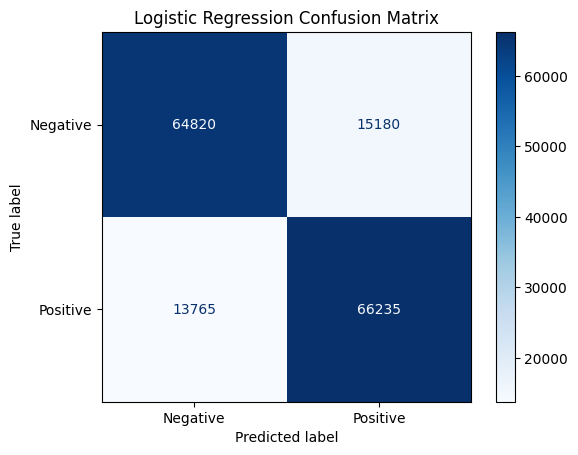

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict sentiment labels on the test set
y_test_pred = lr_model.predict(X_test)

# Calculate evaluation metrics
print(f"Test Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Test Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Test Recall: {recall_score(y_test, y_test_pred):.4f}")
print(f"Test F1 Score: {f1_score(y_test, y_test_pred):.4f}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test, y_test_pred,
    target_names=["Negative", "Positive"]
))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

**Observation: Model Evaluation**

The Logistic Regression model achieved a test accuracy of 81.91%, precision of 81.35%, recall of 82.79%, and F1 score of 82.07%.

The test results were close to the validation performance (81.97% accuracy and 82.14% F1 score), indicating relatively consistent performance across the two evaluation sets.

The confusion matrix shows that 64,820 negative tweets and 66,235 positive tweets were correctly classified. However, 15,180 negative tweets were misclassified as positive, while 13,765 positive tweets were misclassified as negative.

Overall, the model provides a useful traditional machine learning baseline for sentiment classification. However, the previously identified overlapping texts across datasets may affect the reliability of the evaluation results.